# 01 — Titanic: profiling, cleaning and the data story

**Pipeline position:** this notebook performs the **one and only** load of the raw dataset
(`sns.load_dataset('titanic')`), immediately saves it to `titanic.csv` as the committed offline
fallback, then profiles, cleans and explores it. `02_modeling.ipynb` continues from that same
`titanic.csv` and the same cleaning rules in `cleaning.py` — it never calls `sns.load_dataset` again.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from cleaning import full_clean, missing_report

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

## Task 1 — Load once, save the offline fallback, profile

In [2]:
# The single load of the raw dataset for the whole module (network first time, then seaborn's cache).
try:
    df_raw = sns.load_dataset("titanic")
    df_raw.to_csv("titanic.csv", index=False)      # committed offline fallback
    print("Loaded via sns.load_dataset('titanic') and saved titanic.csv")
except Exception as exc:                            # no internet at grading time
    df_raw = pd.read_csv("titanic.csv")
    print(f"sns.load_dataset unavailable ({type(exc).__name__}); loaded committed titanic.csv")

print("shape:", df_raw.shape)

Loaded via sns.load_dataset('titanic') and saved titanic.csv
shape: (891, 15)


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [4]:
df_raw.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
df_raw.describe(exclude='number')

,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537


In [6]:
miss = missing_report(df_raw)
miss

,n_missing,pct_missing,rule
embarked,2,0.22,< 5%: drop rows
embark_town,2,0.22,< 5%: drop rows
age,177,19.87,5-30%: impute
deck,688,77.22,> 30%: drop column or 'missing' category


In [7]:
balance = df_raw["survived"].value_counts(normalize=True).rename({0: "died (0)", 1: "survived (1)"}) * 100
print("Class balance of the target (%):"); print(balance.round(2).to_string())

Class balance of the target (%):
survived
died (0)        61.62
survived (1)    38.38


## Task 2 — Missing-value handling (threshold rule)

Measured on the raw 891 rows (table above), four columns have missing values. Rule: **< 5% → drop rows, 5–30% → impute, too high → drop column or encode "missing" as its own category.**

| Column | Missing | Rule triggered | Decision |
|---|---|---|---|
| `embarked` | 2 rows = **0.22%** | < 5% → drop rows | Drop the 2 rows (891 → 889). |
| `embark_town` | 2 rows = **0.22%** | < 5% → drop rows | Same 2 passengers as `embarked` (it is the same information spelled out), so the same drop fixes both. |
| `age` | 177 rows = **19.87%** | 5–30% → impute | Impute with the **median age within each `sex` × `pclass` group**. The median is robust to the right tail of ages, and grouping keeps the strong class/age link (1st-class passengers were older) instead of pulling everyone to one global value. |
| `deck` | 688 rows = **77.22%** | > 30% → imputation unreliable | Imputing would invent a deck for more than 3 of every 4 passengers, so instead **`Unknown` is encoded as its own category**. I keep the column rather than drop it because the missingness carries information: a deck is recorded for 81.0% of 1st-class passengers but only 8.7% of 2nd and 2.4% of 3rd, and passengers with a known deck survived at 67.0% vs 29.9% for `Unknown`. (The models in `02_modeling` still leave `deck` out, since `pclass` and `fare` already carry that signal.) |

These rules live in `cleaning.py` so that `02_modeling.ipynb` applies exactly the same decisions.

In [8]:
df = full_clean(df_raw)   # structural_clean (drop embarked rows, deck -> 'Unknown') + age imputation
print("rows before:", len(df_raw), "-> after:", len(df))
print("remaining missing values per column:"); print(df.isna().sum()[df.isna().sum() > 0].to_string() or "none")
print("\ndeck categories:"); print(df["deck"].value_counts().to_string())

rows before: 891 -> after: 889
remaining missing values per column:
Series([], )

deck categories:
deck
Unknown    688
C           59
B           45
D           33
E           32
A           15
F           13
G            4


## Task 3 — Univariate analysis: `age` and `fare`

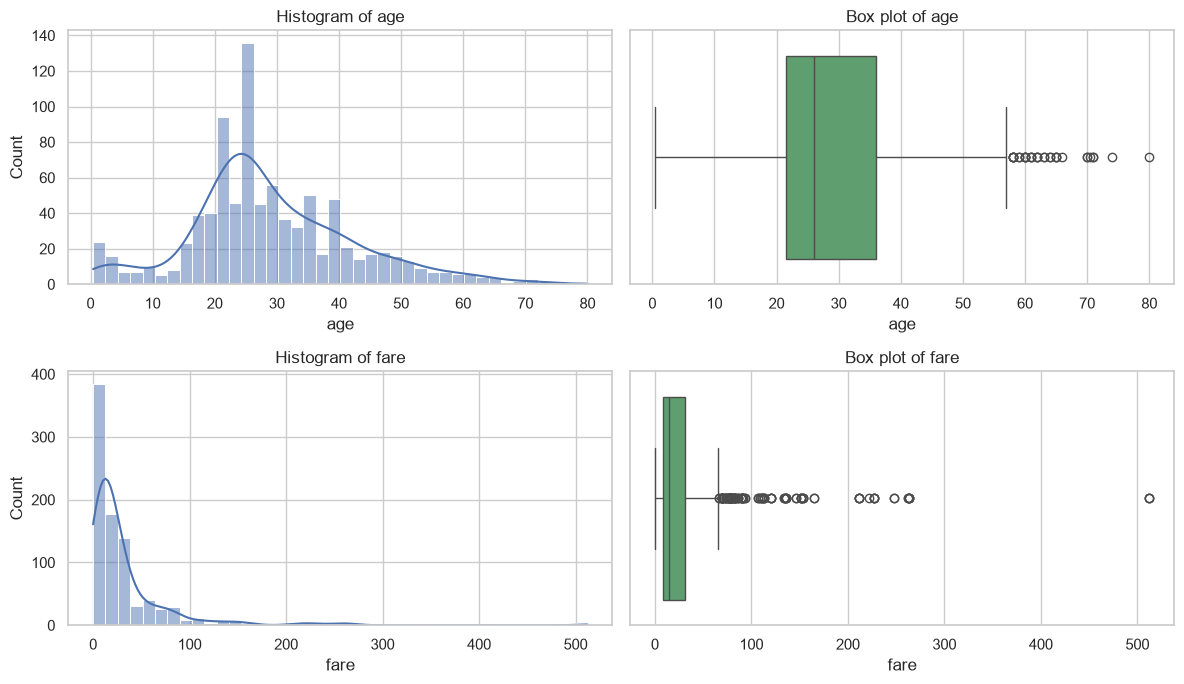

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, col in enumerate(["age", "fare"]):
    sns.histplot(df[col], bins=40, kde=True, ax=axes[row, 0], color="#4C72B0")
    axes[row, 0].set_title(f"Histogram of {col}")
    sns.boxplot(x=df[col], ax=axes[row, 1], color="#55A868")
    axes[row, 1].set_title(f"Box plot of {col}")
plt.tight_layout(); plt.savefig(FIG / "01_univariate_age_fare.png", dpi=110); plt.show()

In [10]:
def iqr_outliers(s: pd.Series) -> dict:
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return {"Q1": q1, "Q3": q3, "IQR": iqr, "lower_fence": lo, "upper_fence": hi,
            "n_outliers": int(((s < lo) | (s > hi)).sum()),
            "n_low": int((s < lo).sum()), "n_high": int((s > hi).sum())}

outliers = pd.DataFrame({
    "age (cleaned, imputed)": iqr_outliers(df["age"]),
    "age (raw, non-missing only)": iqr_outliers(df_raw["age"].dropna()),
    "fare (cleaned)": iqr_outliers(df["fare"]),
}).T
outliers.round(2)

,Q1,Q3,IQR,lower_fence,upper_fence,n_outliers,n_low,n_high
"age (cleaned, imputed)",21.50,36.0,14.50,-0.25,57.75,32.0,0.0,32.0
"age (raw, non-missing only)",20.12,38.0,17.88,-6.69,64.81,11.0,0.0,11.0
fare (cleaned),7.90,31.0,23.10,-26.76,65.66,114.0,0.0,114.0


In [11]:
fare_stats = {"mean": df["fare"].mean(), "median": df["fare"].median(),
              "mode": df["fare"].mode().iloc[0], "skewness": df["fare"].skew()}
pd.Series(fare_stats).round(3)

mean        32.097
median      14.454
mode         8.050
skewness     4.801
dtype: float64

**Outliers (IQR rule).** `fare` has **114 outliers**, all above the upper fence of 65.66 (Q1 = 7.90, Q3 = 31.00, IQR = 23.10); none fall below the lower fence. `age` (after cleaning) has **32 outliers**, all above 57.75 (Q1 = 21.5, Q3 = 36.0, IQR = 14.5). On the raw non-missing ages there are only 11 (fence 64.81). The difference comes from the imputation: placing 177 values at group medians packs the middle of the distribution and narrows the IQR from 17.88 to 14.5 years. I keep all of these rows. They are real elderly passengers and real luxury fares, not data-entry errors.

**Skewness of `fare`.** mean = **32.10** > median = **14.45** > mode = **8.05**, so **`fare` is strongly right-skewed** (positively skewed; sample skewness = 4.80). Most passengers paid cheap 3rd-class fares near the mode, while a small number of very expensive 1st-class tickets (up to 512.33) pull the mean far to the right of the median. That long right tail also explains why the box plot shows so many high-side outliers.

## Task 4 — Bivariate analysis

### Survival rates via boolean masking

In [12]:
def rate(mask):
    return round(df.loc[mask, "survived"].mean() * 100, 2)

male, female = df["sex"] == "male", df["sex"] == "female"
by_sex = pd.Series({"female": rate(female), "male": rate(male)}, name="survival_%")
by_class = pd.Series({f"pclass {c}": rate(df["pclass"] == c) for c in (1, 2, 3)}, name="survival_%")
by_sex_class = pd.DataFrame(
    {sex: {f"pclass {c}": rate((df["sex"] == sex) & (df["pclass"] == c)) for c in (1, 2, 3)}
     for sex in ("female", "male")})

# a couple of explicit &/| combinations for the story
women_or_children = female | (df["age"] < 16)
extra = pd.Series({
    "female & pclass in (1,2)": rate(female & ((df["pclass"] == 1) | (df["pclass"] == 2))),
    "male & pclass == 3": rate(male & (df["pclass"] == 3)),
    "female | age < 16 (women or children)": rate(women_or_children),
    "male & age >= 16 (adult men)": rate(male & (df["age"] >= 16)),
}, name="survival_%")

print("(a) by sex\n", by_sex.to_string(), "\n")
print("(b) by pclass\n", by_class.to_string(), "\n")
print("(c) by sex x pclass (%)\n", by_sex_class.to_string(), "\n")
print("extra &/| combinations\n", extra.to_string())

(a) by sex
 female    74.04
male      18.89 

(b) by pclass
 pclass 1    62.62
pclass 2    47.28
pclass 3    24.24 

(c) by sex x pclass (%)
           female   male
pclass 1   96.74  36.89
pclass 2   92.11  15.74
pclass 3   50.00  13.54 

extra &/| combinations
 female & pclass in (1,2)                 94.64
male & pclass == 3                       13.54
female | age < 16 (women or children)    71.59
male & age >= 16 (adult men)             16.39


**Reading the breakdowns.** Sex is the dominant factor: **74.04%** of women survived vs **18.89%** of men. Class matters too, with a monotone gradient of **62.62% → 47.28% → 24.24%** from 1st to 3rd class. Combined, the gap is stark: 1st- and 2nd-class women survived at **96.74%** and **92.11%**, while 3rd-class women survived at only **50.00%**. Men stay low everywhere, with **36.89%** in 1st class and just **15.74%** / **13.54%** in 2nd / 3rd. The `&`/`|` masks agree: "women or children (< 16)" survived at 71.59% vs 16.39% for adult men.

### Correlation matrix — exactly `survived, pclass, age, sibsp, parch, fare`

`adult_male` and `alone` are excluded: they are derived flags (from sex/age and sibsp+parch) rather than independent measured features.

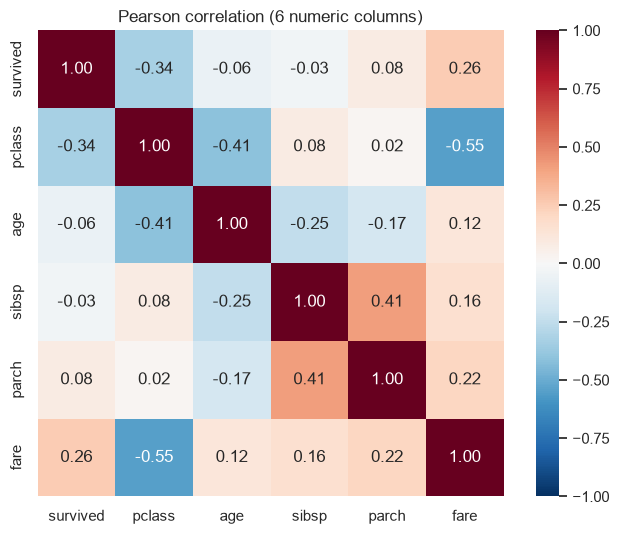

r  abs_r
pclass   fare   -0.548  0.548
sibsp    parch   0.415  0.415
pclass   age    -0.411  0.411
survived pclass -0.336  0.336
         fare    0.255  0.255
age      sibsp  -0.249  0.249
parch    fare    0.218  0.218
age      parch  -0.175  0.175
sibsp    fare    0.161  0.161
age      fare    0.120  0.120
survived parch   0.083  0.083
pclass   sibsp   0.082  0.082
survived age    -0.064  0.064
         sibsp  -0.034  0.034
pclass   parch   0.017  0.017

In [13]:
CORR_COLS = ["survived", "pclass", "age", "sibsp", "parch", "fare"]
corr = df[CORR_COLS].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Pearson correlation (6 numeric columns)")
plt.tight_layout(); plt.savefig(FIG / "02_correlation_heatmap.png", dpi=110); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
         .rename("r").to_frame().assign(abs_r=lambda t: t.r.abs())
         .sort_values("abs_r", ascending=False))
pairs.round(3)

**The two strongest correlations** are the off-diagonal pairs with the largest |r| (ranked table above):

1. **`pclass`–`fare`: r = −0.548.** Higher class *number* (a cheaper class) goes with a lower fare. This is the ticket-pricing structure: median non-zero fare is 61.98 in 1st class, 15.02 in 2nd and 8.05 in 3rd. The two columns largely encode the same socio-economic signal, which is worth remembering for linear models (collinearity).
2. **`sibsp`–`parch`: r = +0.415.** Passengers travelling with siblings/spouses also tended to travel with parents/children, because both counts rise together for family groups.

(Third, just behind, is `pclass`–`age` at −0.411: older passengers were more often in 1st class.) For the target itself, `survived` correlates most with `pclass` (−0.336) and `fare` (+0.255). Sex is not in this numeric-only matrix, but the masks above show it is the strongest driver of all.

## Task 5 — Multivariate data story: who survived, and why?

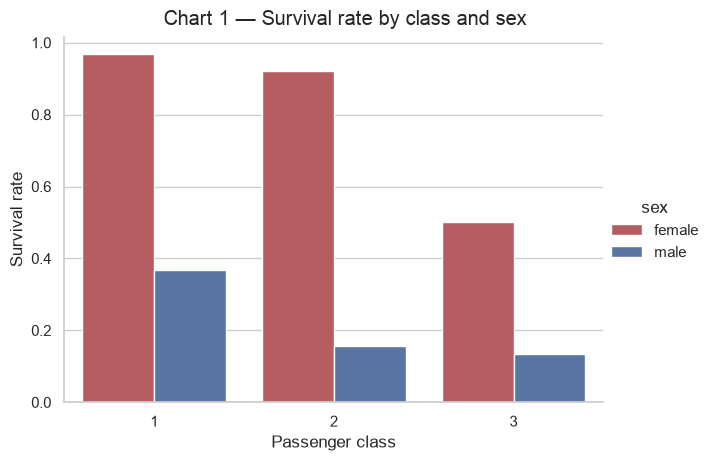

In [14]:
ax = sns.catplot(data=df, x="pclass", y="survived", hue="sex", kind="bar", errorbar=None,
                 height=4.5, aspect=1.4, palette={"female": "#C44E52", "male": "#4C72B0"})
ax.set_axis_labels("Passenger class", "Survival rate")
ax.figure.suptitle("Chart 1 — Survival rate by class and sex", y=1.02)
plt.savefig(FIG / "03_story_class_sex.png", dpi=110, bbox_inches="tight"); plt.show()

**Chart 1 — Class × sex.** Within every class, women's survival bars sit far above men's, and within each sex survival falls as class goes from 1st to 3rd. The "women first" rule was applied almost completely in 1st and 2nd class (96.7% and 92.1%), but only half of 3rd-class women survived. So sex sets the baseline, and class decides how much of that advantage a woman could actually use. This chart sets up the two main axes of the story.

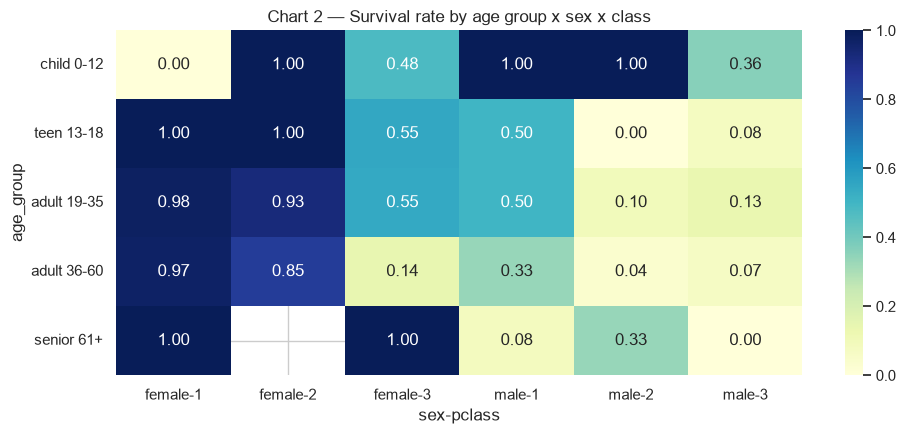

sex         female              male            
pclass           1     2     3     1     2     3
age_group                                       
child 0-12    0.00  1.00  0.48  1.00  1.00  0.36
teen 13-18    1.00  1.00  0.55  0.50  0.00  0.08
adult 19-35   0.98  0.93  0.55  0.50  0.10  0.13
adult 36-60   0.97  0.85  0.14  0.33  0.04  0.07
senior 61+    1.00   NaN  1.00  0.08  0.33  0.00



,mean,size
age_group,,
child 0-12,0.580,69
teen 13-18,0.429,70
adult 19-35,0.358,514
adult 36-60,0.381,215
senior 61+,0.190,21


In [15]:
df["age_group"] = pd.cut(df["age"], bins=[0, 12, 18, 35, 60, 80],
                         labels=["child 0-12", "teen 13-18", "adult 19-35", "adult 36-60", "senior 61+"])
pivot = df.pivot_table(index="age_group", columns=["sex", "pclass"], values="survived",
                       aggfunc="mean", observed=False)
plt.figure(figsize=(10, 4.5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Chart 2 — Survival rate by age group x sex x class")
plt.tight_layout(); plt.savefig(FIG / "04_story_age_sex_class.png", dpi=110); plt.show()
print(pivot.round(2).to_string()); print()
df.groupby("age_group", observed=False)["survived"].agg(["mean", "size"]).round(3)

**Chart 2 — Age group × sex × class heatmap.** Women in 1st/2nd class survive at 0.85–1.00 at almost every age, while adult men (19–60) in 2nd/3rd class survive at only 0.04–0.13. Age helps mostly for boys: males aged 0–12 survived at 1.00 in 1st and 2nd class and 0.36 in 3rd, versus 0.13 for 3rd-class men aged 19–35. Across everyone, children 0–12 survived at 58.0% vs 35.8% for adults 19–35 and 19.0% for seniors 61+. Some cells are tiny: the 0.00 for 1st-class girls is a single passenger, and the 1.00 for 3rd-class senior women is also very small. Those cells should be read as anecdotes, not rates.

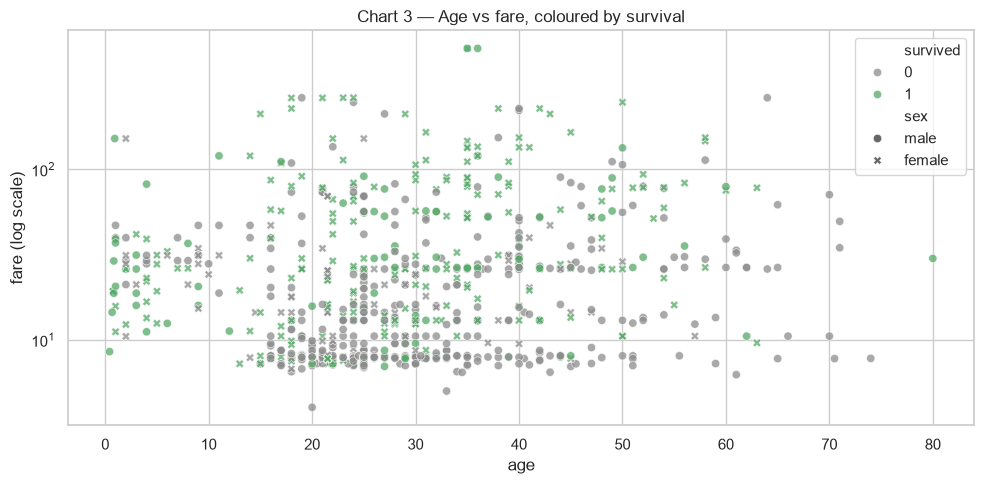

fare_quartile
Q1 low     0.197
Q2         0.304
Q3         0.455
Q4 high    0.577
Name: survived, dtype: float64

In [16]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df[df.fare > 0], x="age", y="fare", hue="survived", style="sex",
                palette={0: "#8C8C8C", 1: "#55A868"}, alpha=0.75)
plt.yscale("log"); plt.ylabel("fare (log scale)")
plt.title("Chart 3 — Age vs fare, coloured by survival")
plt.tight_layout(); plt.savefig(FIG / "05_story_age_fare_scatter.png", dpi=110); plt.show()
df.assign(fare_quartile=pd.qcut(df.fare, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])) \
  .groupby("fare_quartile", observed=False)["survived"].mean().round(3)

**Chart 3 — Age vs fare scatter (log fare).** Survivors (green) cluster in the upper band of fares and dying passengers (grey) dominate the dense low-fare strip around 7–15. Survival rises steadily by fare quartile: **19.7% → 30.4% → 45.5% → 57.7%**. Fare acts as a proxy for class and cabin location (closer to the boat deck), so it repeats Chart 1's class effect in continuous form. Across all ages, the low-fare deaths are mostly men (the marker style shows sex).

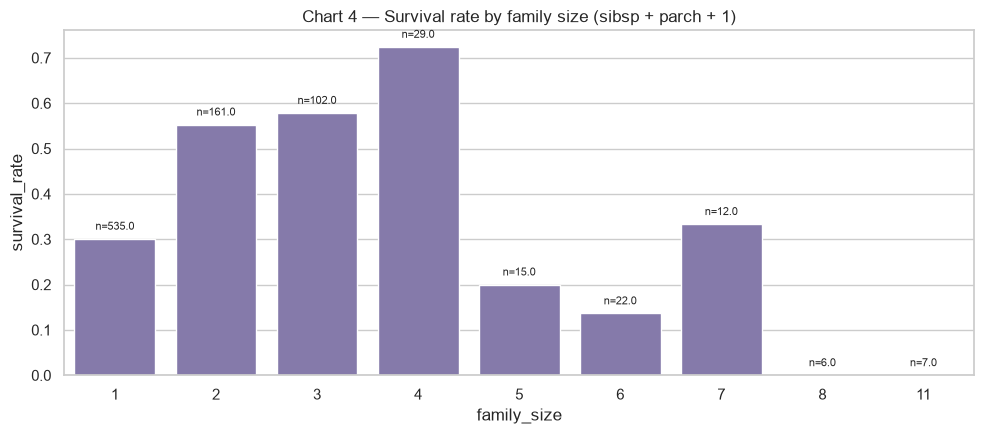

,family_size,survival_rate,passengers
0,1,0.301,535
1,2,0.553,161
2,3,0.578,102
3,4,0.724,29
4,5,0.200,15
5,6,0.136,22
6,7,0.333,12
7,8,0.000,6
8,11,0.000,7


In [17]:
df["family_size"] = df["sibsp"] + df["parch"] + 1
fam = df.groupby("family_size")["survived"].agg(survival_rate="mean", passengers="size").reset_index()
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=fam, x="family_size", y="survival_rate", color="#8172B2", ax=ax)
for i, r in fam.iterrows():
    ax.text(i, r.survival_rate + 0.02, f"n={r.passengers}", ha="center", fontsize=8)
ax.set_title("Chart 4 — Survival rate by family size (sibsp + parch + 1)")
plt.tight_layout(); plt.savefig(FIG / "06_story_family_size.png", dpi=110); plt.show()
fam.round(3)

**Chart 4 — Family size.** Survival is non-monotone. Passengers travelling alone (n = 535) survived at 30.1%, small families of 2–4 did best (55.3%, 57.8%, 72.4%), and large families of 5+ collapsed (20.0%, 13.6%, 33.3%, then 0% for sizes 8 and 11). Large families were overwhelmingly 3rd class (54 of the 62 passengers in families of 5+), and they had to find and move many people at once. Solo travellers were mostly adult men. That explains why both extremes do badly, and it suggests a non-linear "family size" effect a linear model would miss.

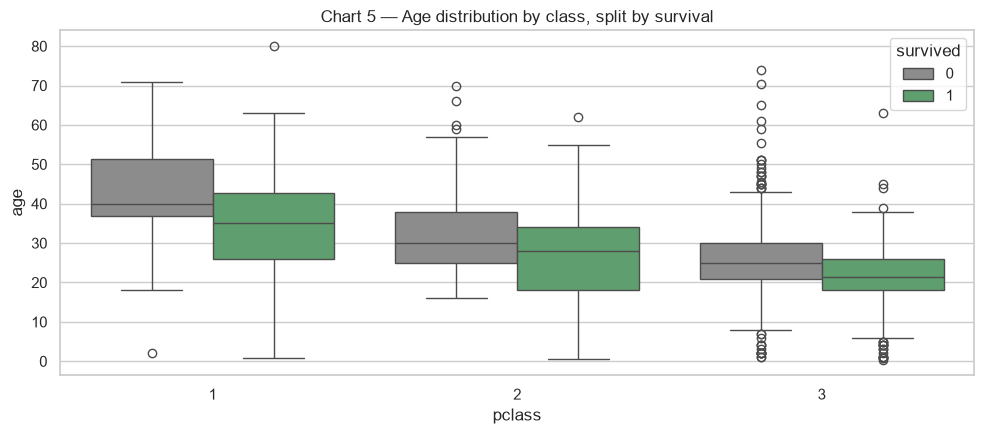

survived,0,1
pclass,,
1,40.0,35.0
2,30.0,28.0
3,25.0,21.5


In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df, x="pclass", y="age", hue="survived", palette={0: "#8C8C8C", 1: "#55A868"}, ax=ax)
ax.set_title("Chart 5 — Age distribution by class, split by survival")
plt.tight_layout(); plt.savefig(FIG / "07_story_age_class_box.png", dpi=110); plt.show()
df.groupby(["pclass", "survived"])["age"].median().unstack().round(1)

**Chart 5 — Age by class, split by survival.** 1st-class passengers were older overall, which matches the `pclass`–`age` correlation of −0.41. In every class, survivors were younger than non-survivors: median age **35.0 vs 40.0** in 1st, **28.0 vs 30.0** in 2nd, **21.5 vs 25.0** in 3rd. The age effect is modest compared with sex and class, but it points the same way as the "children first" pattern in Chart 2.

### The story in one paragraph
Survival on the Titanic was decided first by **sex** (74% of women vs 19% of men), then by **class/wealth** (63% → 47% → 24% from 1st to 3rd class, and 20% → 58% from the lowest to the highest fare quartile), and then, to a lesser degree, by **age** (children 0–12: 58%) and **group size** (small families did best; solo travellers and large, mostly 3rd-class families did worst). The evacuation followed "women and children first", but access to the boats depended on class. That is why a 3rd-class woman had only a coin-flip chance (50%) while a 1st-class woman almost always survived (97%). These patterns tell the modeling notebook which features to use: `sex`, `pclass`, `fare`, `age`, `sibsp`, `parch` and `embarked`.

## Task 6 — Exploratory z-score standardization check (`age`, `fare`)

Computed manually as `z = (x − mean) / std` on the full cleaned DataFrame. This is an EDA sanity check only — the modeling pipeline fits its own `StandardScaler` on the training split.

In [19]:
z = df[["age", "fare"]].copy()
for col in ["age", "fare"]:
    z[f"{col}_z"] = (df[col] - df[col].mean()) / df[col].std()

summary = pd.DataFrame({
    "mean": z.mean(), "std": z.std(), "min": z.min(), "max": z.max()
}).round(4)
summary

,mean,std,min,max
age,29.0654,13.2702,0.4200,80.0000
fare,32.0967,49.6975,0.0000,512.3292
age_z,0.0000,1.0000,-2.1586,3.8383
fare_z,0.0000,1.0000,-0.6458,9.6631


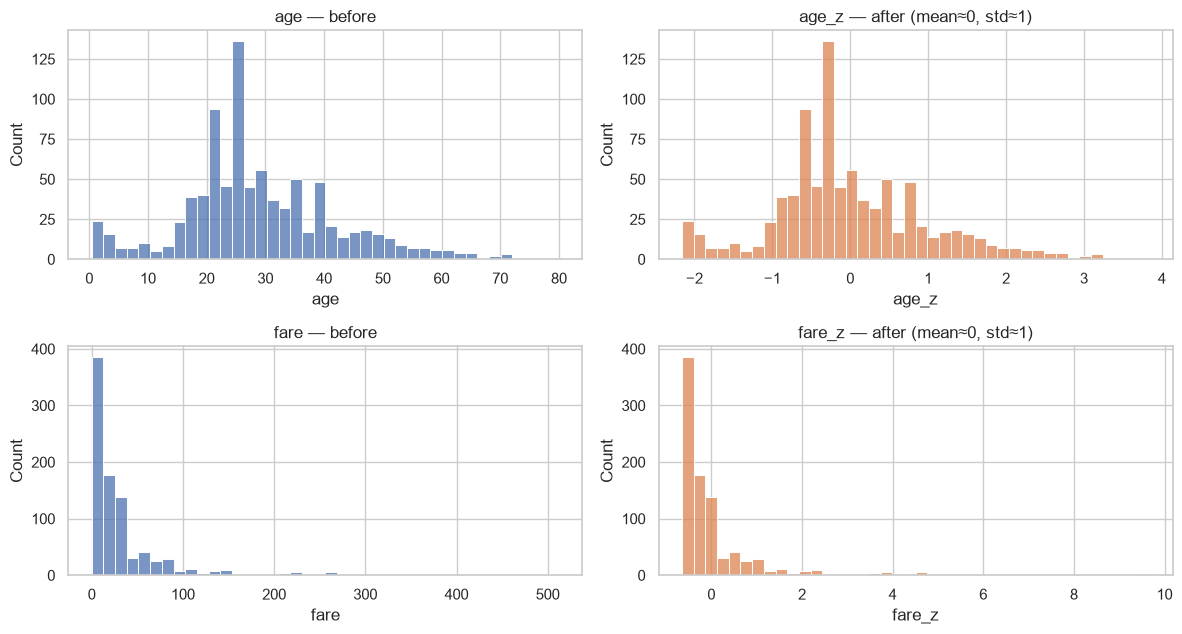

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
for i, col in enumerate(["age", "fare"]):
    sns.histplot(z[col], bins=40, ax=axes[i, 0], color="#4C72B0"); axes[i, 0].set_title(f"{col} — before")
    sns.histplot(z[f"{col}_z"], bins=40, ax=axes[i, 1], color="#DD8452"); axes[i, 1].set_title(f"{col}_z — after (mean≈0, std≈1)")
plt.tight_layout(); plt.savefig(FIG / "08_zscore_before_after.png", dpi=110); plt.show()

**Check passed.** Before scaling, `age` has mean 29.07 / std 13.27 and `fare` has mean 32.10 / std 49.70. After `z = (x − mean) / std`, both `age_z` and `fare_z` have **mean 0.0000 and std 1.0000**. The overlaid histograms show that the *shape* is unchanged: `fare_z` is still right-skewed, with a max of 9.66 standard deviations. A z-score is a linear shift-and-rescale, so it puts features on a common scale for distance- or gradient-based models but does not remove skew or outliers (that would need e.g. a log transform). This check is exploratory only; the modeling pipeline fits its own `StandardScaler` on the training split alone.